# Lesson 03 — URDF: Describe a Robot's Body

*Before a robot can move, ROS 2 must know what it looks like and how its parts connect. In this lesson you write a URDF file, see your robot in 3D, and move its joints with sliders.*

---

<!-- video: insert Vimeo embed here -->

---

## 🎯 By the end of this lesson you can

- Write a URDF file with links and joints
- See your robot in 3D with `rviz2()`
- Move its joints with sliders
- Explain how a URDF and joint values become coordinate frames

---

---

## 🧰 Setup — run once

If the demo robot from lesson 02 is still running in another notebook, run `stop_demo_robot()` there first.

In [1]:
import sys
sys.path.insert(0, "scripts")
from rosforge_tools import start_robot, stop_robot, rviz2, joint_sliders, rqt_graph

---

## 🚀 Do it — your first robot: one box

A URDF is a text file in XML. Run the cell below to write the smallest useful one. It has a single **link**, `base_link`, drawn as a blue box 0.3 m long, 0.2 m wide and 0.08 m high.

In [2]:
%%writefile my_robot.urdf
<robot name="my_robot">
  <material name="blue"><color rgba="0.2 0.4 0.9 1"/></material>
  <material name="dark"><color rgba="0.15 0.15 0.18 1"/></material>
  <material name="red"><color rgba="0.9 0.2 0.2 1"/></material>

  <link name="base_link">
    <visual>
      <geometry>
        <box size="0.3 0.2 0.08"/>
      </geometry>
      <material name="blue"/>
    </visual>
  </link>
</robot>

Overwriting my_robot.urdf


Now start `robot_state_publisher`, the ROS 2 program that publishes the robot's description and its frames:

In [4]:
start_robot("my_robot.urdf")

robot_state_publisher is running with my_robot.urdf


In a Terminal you would type:

```bash
cd ~/course_materials
ros2 run robot_state_publisher --ros-args -p robot_description:="$(cat my_robot.urdf)"
```

Open the 3D view:

In [ ]:
rviz2()

[WARN] [1791484485.458758740] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1791484485.458786953] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


You see a blue box and the axes of its frame, `base_link`.

---

---

## 🔍 Explore — change the robot

Edit the URDF cell above, then run it again followed by `start_robot("my_robot.urdf")`. The 3D view above updates by itself.

- Make the box longer: change `0.3` to `0.4`.
- Change its color: edit `rgba` in the `blue` material (red, green, blue, opacity, each from 0 to 1).
- Break it on purpose: delete a closing tag, and run `start_robot` again. Read the message.

---

---

## 🚀 Do it — add a wheel that turns

A wheel is a second link. A **joint** connects it to the base. Run the cell below to add a left wheel with a red mark, so you can see it turn:

In [5]:
%%writefile my_robot.urdf
<robot name="my_robot">
  <material name="blue"><color rgba="0.2 0.4 0.9 1"/></material>
  <material name="dark"><color rgba="0.15 0.15 0.18 1"/></material>
  <material name="red"><color rgba="0.9 0.2 0.2 1"/></material>

  <link name="base_link">
    <visual>
      <geometry>
        <box size="0.3 0.2 0.08"/>
      </geometry>
      <material name="blue"/>
    </visual>
  </link>

  <link name="left_wheel">
    <visual>
      <origin rpy="1.5708 0 0"/>
      <geometry>
        <cylinder radius="0.05" length="0.03"/>
      </geometry>
      <material name="dark"/>
    </visual>
    <visual>
      <origin xyz="0.04 0 0"/>
      <geometry>
        <box size="0.02 0.034 0.02"/>
      </geometry>
      <material name="red"/>
    </visual>
  </link>

  <joint name="left_wheel_joint" type="continuous">
    <parent link="base_link"/>
    <child link="left_wheel"/>
    <origin xyz="0 0.115 0"/>
    <axis xyz="0 1 0"/>
  </joint>
</robot>

Overwriting my_robot.urdf


In [6]:
start_robot("my_robot.urdf")

robot_state_publisher is running with my_robot.urdf


Open a fresh 3D view, and the sliders for the robot's joints:

In [7]:
rviz2()

[WARN] [1791468105.585462140] [rcl.logging_rosout]: Publisher already registered for node name: 'rosforge_rviz2'. If this is due to multiple nodes with the same name then all logs for the logger named 'rosforge_rviz2' will go out over the existing publisher. As soon as any node with that name is destructed it will unregister the publisher, preventing any further logs for that name from being published on the rosout topic.


In [8]:
joint_sliders()

You see one slider, `left_wheel_joint`. Move it: the wheel turns and the red mark goes around.

---

---

## 🔍 Explore — follow the data

**What is published now?**

In [9]:
!ros2 topic list

[WARN] [1791468133.481575601] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1791468133.481612270] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.
/joint_states
/map
/parameter_events
/robot_description
/rosout
/scan
/tf
/tf_static


You see `/robot_description`, `/joint_states`, `/tf` and `/tf_static`.

**Where is the wheel?** Ask ROS 2 for the position of `left_wheel` in the frame `base_link`. Run it, move the slider, then run it again:

In [10]:
!timeout 3 ros2 run tf2_ros tf2_echo base_link left_wheel

[WARN] [1791468138.385828758] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1791468138.385866618] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.
[INFO] [1791468138.566847295] [tf2_echo]: Waiting for transform base_link ->  left_wheel: Invalid frame ID "base_link" passed to canTransform argument target_frame - frame does not exist
At time 1791468139.364031202
- Translation: [0.000, 0.115, 0.000]
- Rotation: in Quaternion (xyzw) [0.000, -0.622, 0.000, 0.783]
- Rotation: in RPY (radian) [0.000, -1.342, 0.000]
- Rotation: in RPY (degree) [0.000, -76.868, 0.000]
- Matrix:
  0.227 -0.000 -0.974  0.000
  0.000  1.000 -0.000  0.115
  0.974  0.000  0.227  0.000
  0.000  0.000  0.000  1.000
[INFO] [1791468140.069385316] [rclcpp]: signal_handler(SIGINT/SIGTERM)


The translation stays `[0.000, 0.115, 0.000]`: that is the joint's `origin`. The rotation changes when you move the slider.

**Who talks to whom?**

In [11]:
rqt_graph()

You see the sliders publishing `/joint_states`, `/robot_state_publisher` subscribing to it and publishing `/tf`, and the 3D view subscribing to `/tf`.

---

---

## 💡 What you just saw

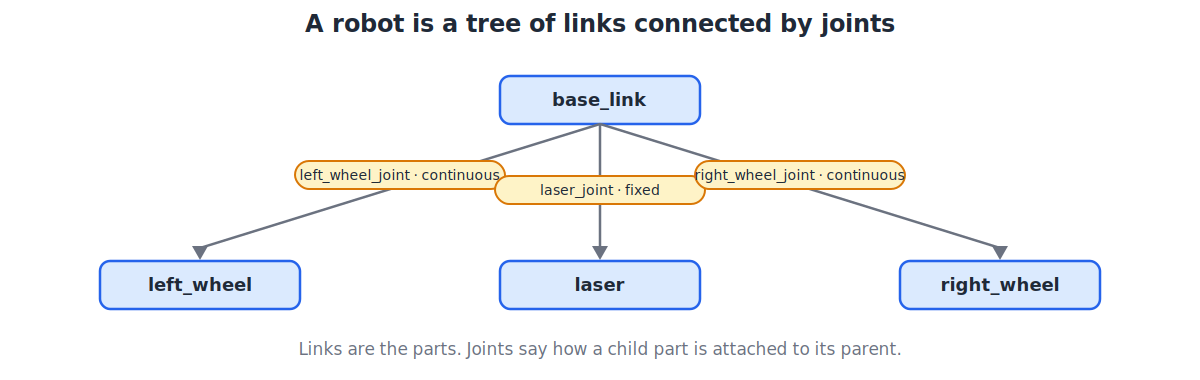

- A **link** is a rigid part. Its `<visual>` says what it looks like: a `box`, `cylinder`, `sphere` or `mesh`, with a color.
- A **joint** attaches a **child** link to a **parent** link. Its `<origin xyz="..." rpy="..."/>` is the child's position and rotation relative to the parent: `xyz` in meters, `rpy` (roll, pitch, yaw) in radians. Every link also becomes a **coordinate frame**.
- Joint **types** decide how the child can move:

| Type | Motion |
|---|---|
| `fixed` | none (a sensor bolted to the body) |
| `continuous` | turns around its `axis`, without limits (a wheel) |
| `revolute` | turns around its `axis`, between limits (an arm) |
| `prismatic` | slides along its `axis`, between limits |

- A cylinder points along **z** by default. The wheel's visual has `rpy="1.5708 0 0"`, a 90° roll, to lay it on its side.

### From file to frames

The URDF only describes the body. It never moves. The **joint values** (`/joint_states`) say where each joint is right now. `robot_state_publisher` combines both and publishes the frames on `/tf`. That is what `rviz2()` draws, and what the next lesson explains.

A URDF can also hold `<collision>` and `<inertial>` parts, which a physics simulator needs (lesson 05). RViz only needs `<visual>`.

---

---

## 🧠 Challenge — finish the robot

Edit the URDF cell from the second step (or write a new one), then run `start_robot` and `rviz2()` again.

1. Add a **right wheel**, like the left one but on the other side of the body.
2. Add a **laser** on top: a small cylinder attached with a `fixed` joint 0.12 m above `base_link`. Check it with `tf2_echo base_link laser`.
3. **Predict, then test:** what happens if you remove `rpy="1.5708 0 0"` from a wheel?

<details>
<summary>💡 Hint</summary>

Copy the whole left wheel block (the link and its joint). Rename it to `right_wheel` and `right_wheel_joint`, and change the sign of `y` in the joint's `origin`. Use the same wheel `axis`.

</details>

<details>
<summary>✅ Solution</summary>

Add this before `</robot>`:

```xml
  <link name="right_wheel">
    <visual>
      <origin rpy="1.5708 0 0"/>
      <geometry>
        <cylinder radius="0.05" length="0.03"/>
      </geometry>
      <material name="dark"/>
    </visual>
    <visual>
      <origin xyz="0.04 0 0"/>
      <geometry>
        <box size="0.02 0.034 0.02"/>
      </geometry>
      <material name="red"/>
    </visual>
  </link>

  <joint name="right_wheel_joint" type="continuous">
    <parent link="base_link"/>
    <child link="right_wheel"/>
    <origin xyz="0 -0.115 0"/>
    <axis xyz="0 1 0"/>
  </joint>

  <link name="laser">
    <visual>
      <geometry>
        <cylinder radius="0.04" length="0.04"/>
      </geometry>
      <material name="dark"/>
    </visual>
  </link>

  <joint name="laser_joint" type="fixed">
    <parent link="base_link"/>
    <child link="laser"/>
    <origin xyz="0 0 0.12"/>
  </joint>
```

Without the 90° roll, the cylinder stands upright like a drum, because its axis is `z`.

</details>

---

---

## ✅ Check yourself

<details><summary>What is the difference between a link and a joint?</summary>

A link is a rigid part with a shape. A joint connects a child link to a parent link and says where it is attached and how it can move.

</details>

<details><summary>Which joint type fits a wheel? A sensor fixed on the body?</summary>

`continuous` for a wheel, `fixed` for a sensor.

</details>

<details><summary>Does the URDF file change when the wheel turns?</summary>

No. The file describes the body. The wheel's angle comes from the `/joint_states` topic.

</details>

<details><summary>What does <code>robot_state_publisher</code> do?</summary>

It reads the URDF and the joint values, and publishes the position of every link as frames on `/tf`.

</details>

---

---

## 📋 What you learned

- A **URDF** describes a robot as a tree of **links** joined by **joints**
- A joint's `origin` places the child relative to the parent, and its `type` says how it moves
- **`robot_state_publisher`** turns a URDF and `/joint_states` into frames on `/tf`
- `rviz2()` draws the robot, and `joint_sliders()` moves its joints

### Commands reference

| Command | What it does |
|---|---|
| `ros2 run robot_state_publisher robot_state_publisher --ros-args -p robot_description:="$(cat file.urdf)"` | Publish a robot from a URDF file |
| `ros2 run tf2_ros tf2_echo <from> <to>` | Print where one frame is in another |
| `ros2 topic echo /joint_states` | Print the joint values |

When you finish, stop the robot publisher:

In [ ]:
stop_robot()

---

> **Next lesson:** you look closely at TF, the frames that tell every part of the robot where it is.